# Chapter 15: A/B Testing

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 15.1 Why an Experiment Shows Cause

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import (
    proportions_ztest, proportion_confint,
    confint_proportions_2indep, proportion_effectsize)
from statsmodels.stats.power import NormalIndPower, TTestIndPower
from statsmodels.stats.multitest import multipletests

plt.style.use('book.mplstyle')


def p_text(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


visitors = pd.read_csv('ab_test.csv', parse_dates=['visit_date'])
visitors[['visit_date', 'group', 'device', 'started_checkout',
          'purchased', 'order_value']].head()

,visit_date,group,device,started_checkout,purchased,order_value
0,2025-10-06,control,Mobile,1,0,NaN
1,2025-10-06,new,Mobile,0,0,NaN
2,2025-10-06,new,Mobile,0,0,NaN
3,2025-10-06,new,Mobile,0,0,NaN
4,2025-10-06,control,Mobile,0,0,NaN


### Random assignment

In [2]:
pd.crosstab(visitors['group'], visitors['device'],
            normalize='index').round(3)

device,Desktop,Mobile
group,,
control,0.379,0.621
new,0.375,0.625


### Checking the split

In [3]:
group_sizes = visitors['group'].value_counts()
group_sizes

group
control    11386
new        11370
Name: count, dtype: int64

In [4]:
n_visitors = group_sizes.sum()
smaller = group_sizes.min()
split_p = 2 * stats.binom.cdf(smaller, n=n_visitors, p=0.5)
print(f'New share: {group_sizes["new"] / n_visitors:.1%}')
print(p_text(split_p))

New share: 50.0%
p = 0.921


## 15.2 Comparing Two Rates

In [5]:
buyers = visitors.groupby('group')['purchased'].agg(['sum', 'count',
                                                     'mean'])
buyers = buyers.loc[['new', 'control']]
buyers.round(4)

,sum,count,mean
group,,,
new,1064,11370,0.0936
control,911,11386,0.0800


### `proportions_ztest()`

In [6]:
proportions_ztest(buyers['sum'], buyers['count'])

(np.float64(3.635353548786911), np.float64(0.00027759966198728065))

In [7]:
z_stat, p_value = proportions_ztest(buyers['sum'], buyers['count'])
print(f'z = {z_stat:.2f}, {p_text(p_value)}')

z = 3.64, p < 0.001


### `proportion_confint()`

In [8]:
low, high = proportion_confint(buyers['sum'], buyers['count'])
pd.DataFrame({'rate': buyers['mean'], 'low': low,
              'high': high}).round(4)

,rate,low,high
group,,,
new,0.0936,0.0882,0.0989
control,0.0800,0.0750,0.0850


### `confint_proportions_2indep()`

In [9]:
new, control = buyers.loc['new'], buyers.loc['control']
diff_low, diff_high = confint_proportions_2indep(
    new['sum'], new['count'], control['sum'], control['count'])
lift = new['mean'] - control['mean']
print(f'New minus control: {lift:.2%} points, '
      f'95% CI {diff_low:.2%} to {diff_high:.2%}')
print(f'Relative lift: {lift / control["mean"]:.0%}')

New minus control: 1.36% points, 95% CI 0.63% to 2.09%
Relative lift: 17%


### Yates' correction in `stats.chi2_contingency()`

In [10]:
group_buys = pd.crosstab(visitors['group'], visitors['purchased'])
default = stats.chi2_contingency(group_buys)
no_yates = stats.chi2_contingency(group_buys, correction=False)
print(f'correction=True (default): {default.pvalue:.6f}')
print(f'correction=False:          {no_yates.pvalue:.6f}')
print(f'proportions_ztest:         {p_value:.6f}')
print(f'z squared: {z_stat**2:.2f}, '
      f'chi-square: {no_yates.statistic:.2f}')

correction=True (default): 0.000304
correction=False:          0.000278
proportions_ztest:         0.000278
z squared: 13.22, chi-square: 13.22


## 15.3 Where the New Page Helps

In [11]:
funnel = visitors.groupby('group').agg(
    visited=('visitor_id', 'count'),
    viewed_plans=('viewed_plans', 'sum'),
    started_checkout=('started_checkout', 'sum'),
    purchased=('purchased', 'sum'))
funnel = funnel.loc[['new', 'control']]
funnel

,visited,viewed_plans,started_checkout,purchased
group,,,,
new,11370,6173,3259,1064
control,11386,6207,3191,911


In [12]:
step_rates = pd.DataFrame({
    'view plans': funnel['viewed_plans'] / funnel['visited'],
    'start checkout': (funnel['started_checkout']
                       / funnel['viewed_plans']),
    'buy': funnel['purchased'] / funnel['started_checkout']})
step_rates.round(3)

,view plans,start checkout,buy
group,,,
new,0.543,0.528,0.326
control,0.545,0.514,0.285


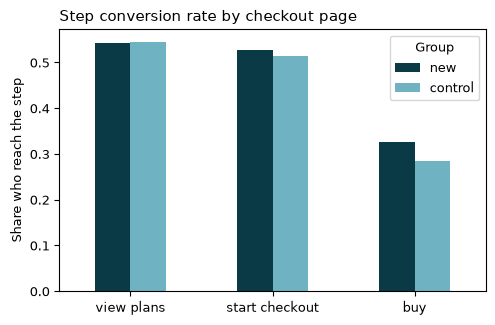

In [13]:
ax = step_rates.T.plot.bar(color=['#0b3a47', '#6fb3c2'], rot=0)
ax.set_title('Step conversion rate by checkout page')
ax.set_ylabel('Share who reach the step')
ax.legend(title='Group')
plt.show()

In [14]:
stages = [('visited', 'viewed_plans'),
          ('viewed_plans', 'started_checkout'),
          ('started_checkout', 'purchased')]
for before, after in stages:
    z_step, p_step = proportions_ztest(funnel[after],
                                       funnel[before])
    print(f'{before:>16} -> {after:<16} {p_text(p_step)}')

         visited -> viewed_plans     p = 0.736
    viewed_plans -> started_checkout p = 0.123
started_checkout -> purchased        p < 0.001


## 15.4 Order Value and Revenue per Visitor

In [15]:
order_value = visitors.groupby('group')['order_value'].agg(
    ['count', 'mean', 'median', 'std'])
order_value.loc[['new', 'control']].round(2)

,count,mean,median,std
group,,,,
new,1064,32.31,30.49,11.98
control,911,32.19,30.32,11.99


In [16]:
new_orders = visitors.loc[visitors['group'] == 'new',
                          'order_value'].dropna()
control_orders = visitors.loc[visitors['group'] == 'control',
                              'order_value'].dropna()
value_test = stats.ttest_ind(new_orders, control_orders,
                             equal_var=False)
value_ci = value_test.confidence_interval()
print(p_text(value_test.pvalue))
print(f'New minus control: '
      f'${new_orders.mean() - control_orders.mean():.2f}, '
      f'95% CI {value_ci.low:.2f} to {value_ci.high:.2f} dollars')

p = 0.820
New minus control: $0.12, 95% CI -0.94 to 1.18 dollars


### Revenue per visitor

In [17]:
visitors['revenue'] = visitors['order_value'].fillna(0)
new_rev = visitors.loc[visitors['group'] == 'new', 'revenue']
control_rev = visitors.loc[visitors['group'] == 'control', 'revenue']
revenue_test = stats.ttest_ind(new_rev, control_rev, equal_var=False)
revenue_ci = revenue_test.confidence_interval()
print(f'New: ${new_rev.mean():.2f}  Control: ${control_rev.mean():.2f}')
print(p_text(revenue_test.pvalue))
gain = new_rev.mean() - control_rev.mean()
print(f'Gain per visitor: ${gain:.2f}, '
      f'95% CI ${revenue_ci.low:.2f} to ${revenue_ci.high:.2f}')
print(f'Times {len(new_rev):,} visitors: ${gain * len(new_rev):,.0f}')

New: $3.02  Control: $2.58
p < 0.001
Gain per visitor: $0.45, 95% CI $0.20 to $0.70
Times 11,370 visitors: $5,097


## 15.5 Planning the Sample Size

### `proportion_effectsize()`

In [18]:
effect = proportion_effectsize(0.09, 0.08)
print(f"Cohen's h for 8% -> 9%: {effect:.3f}")
print(f"Order flipped: {proportion_effectsize(0.08, 0.09):.3f}")

Cohen's h for 8% -> 9%: 0.036
Order flipped: -0.036


### `NormalIndPower()`

In [19]:
needed = NormalIndPower().solve_power(effect_size=effect,
                                      alpha=0.05, power=0.8)
print(f'Visitors needed per group: {needed:,.0f}')
n_days_run = visitors['visit_date'].nunique()
print(f'Visitors per day in the test: '
      f'{len(visitors) / n_days_run:.0f}')

Visitors needed per group: 12,199
Visitors per day in the test: 813


In [20]:
actual_n = group_sizes.min()
actual_power = NormalIndPower().solve_power(
    effect_size=effect, nobs1=actual_n, alpha=0.05)
print(f'Power with {actual_n:,} per group: {actual_power:.0%}')

Power with 11,370 per group: 77%


In [21]:
for target in [0.085, 0.09, 0.095, 0.10]:
    h = proportion_effectsize(target, 0.08)
    n = NormalIndPower().solve_power(effect_size=h, alpha=0.05,
                                     power=0.8)
    print(f'8% -> {target:.1%}: {n:>7,.0f} per group')

8% -> 8.5%:  47,518 per group


8% -> 9.0%:  12,199 per group
8% -> 9.5%:   5,561 per group
8% -> 10.0%:   3,205 per group


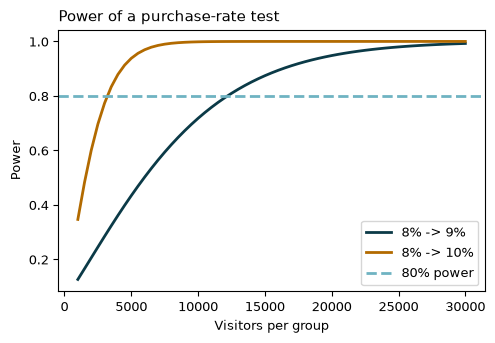

In [22]:
sizes = np.arange(1000, 30001, 500)
fig, ax = plt.subplots()
for target, color in [(0.09, '#0b3a47'), (0.10, '#b26a00')]:
    h = proportion_effectsize(target, 0.08)
    ax.plot(sizes, NormalIndPower().power(h, sizes, 0.05),
            color=color, label=f'8% -> {target:.0%}')
ax.axhline(0.8, color='#6fb3c2', linestyle='--', label='80% power')
ax.set_title('Power of a purchase-rate test')
ax.set_xlabel('Visitors per group')
ax.set_ylabel('Power')
ax.legend()
plt.show()

### `TTestIndPower()`

In [23]:
value_sd = visitors['order_value'].std()
print(f'Order value standard deviation: ${value_sd:.2f}')
for gap in [1, 2]:
    n = TTestIndPower().solve_power(effect_size=gap / value_sd,
                                    alpha=0.05, power=0.8)
    print(f'${gap} change: {n:,.0f} buyers per group')

Order value standard deviation: $11.98
$1 change: 2,255 buyers per group
$2 change: 564 buyers per group


## 15.6 Mobile and Desktop

In [24]:
by_device = visitors.groupby(['device', 'group'])['purchased'].agg(
    ['sum', 'count', 'mean'])
by_device.round(4)

sum  count    mean
device  group                      
Desktop control  385   4314  0.0892
        new      426   4268  0.0998
Mobile  control  526   7072  0.0744
        new      638   7102  0.0898

In [25]:
device_p = {}
for device in ['Mobile', 'Desktop']:
    rows = by_device.loc[device].loc[['new', 'control']]
    z_dev, p_dev = proportions_ztest(rows['sum'], rows['count'])
    low, high = confint_proportions_2indep(
        rows.loc['new', 'sum'], rows.loc['new', 'count'],
        rows.loc['control', 'sum'], rows.loc['control', 'count'])
    gap = rows.loc['new', 'mean'] - rows.loc['control', 'mean']
    device_p[device] = p_dev
    print(f'{device:<8} {gap:.2%} points, '
          f'95% CI {low:.2%} to {high:.2%}, {p_text(p_dev)}')

Mobile   1.55% points, 95% CI 0.64% to 2.45%, p < 0.001
Desktop  1.06% points, 95% CI -0.18% to 2.30%, p = 0.094


In [26]:
desktop = by_device.loc['Desktop']
desktop_h = proportion_effectsize(desktop.loc['new', 'mean'],
                                  desktop.loc['control', 'mean'])
desktop_power = NormalIndPower().solve_power(
    effect_size=desktop_h, nobs1=desktop['count'].min(), alpha=0.05)
print(f'Desktop visitors per group: {desktop["count"].min():,}')
print(f'Power to catch the desktop gain seen here: '
      f'{desktop_power:.0%}')

Desktop visitors per group: 4,268
Power to catch the desktop gain seen here: 39%


### Slicing after the fact

In [27]:
reject, adjusted, _, _ = multipletests(list(device_p.values()),
                                       method='holm')
for device, p_adj in zip(device_p, adjusted):
    print(f'{device:<8} adjusted {p_text(p_adj)}')

Mobile   adjusted p = 0.002
Desktop  adjusted p = 0.094


## 15.7 Common A/B Mistakes

### Peeking

In [28]:
days = visitors['visit_date'].drop_duplicates().sort_values()
daily_p = {}
for day in days:
    so_far = visitors[visitors['visit_date'] <= day]
    counts = so_far.groupby('group')['purchased'].agg(['sum', 'count'])
    daily_p[day] = proportions_ztest(counts['sum'], counts['count'])[1]
daily_p = pd.Series(daily_p)
daily_p.round(3).head(4)

2025-10-06    0.822
2025-10-07    0.609
2025-10-08    0.253
2025-10-09    0.158
dtype: float64

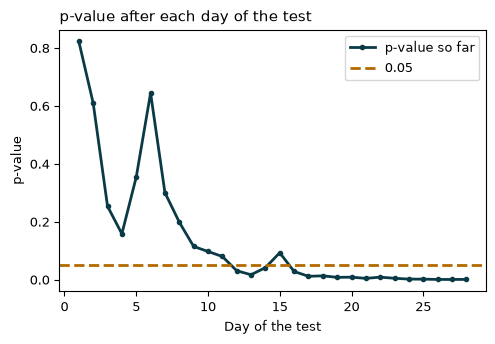

In [29]:
by_day_number = pd.Series(daily_p.to_numpy(),
                          index=np.arange(1, len(daily_p) + 1))
ax = by_day_number.plot(color='#0b3a47', marker='o', markersize=3,
                        label='p-value so far')
ax.axhline(0.05, color='#b26a00', linestyle='--', label='0.05')
ax.set_title('p-value after each day of the test')
ax.set_xlabel('Day of the test')
ax.set_ylabel('p-value')
ax.legend()
plt.show()

In [30]:
first_below = (daily_p < 0.05).idxmax()
print(f'First day below 0.05: {first_below.date()}')
daily_p.round(3).iloc[10:16]

First day below 0.05: 2025-10-17


2025-10-16    0.080
2025-10-17    0.030
2025-10-18    0.016
2025-10-19    0.041
2025-10-20    0.092
2025-10-21    0.028
dtype: float64

### An A/A test

In [31]:
rng = np.random.default_rng(42)
per_day, n_days = 400, 28
seen = per_day * np.arange(1, n_days + 1)
ever_below, below_at_end = 0, 0
for _ in range(1000):
    buys_a = stats.binom.rvs(n=per_day, p=0.08, size=n_days,
                             random_state=rng).cumsum()
    buys_b = stats.binom.rvs(n=per_day, p=0.08, size=n_days,
                             random_state=rng).cumsum()
    p_values = []
    for d in range(n_days):
        p_values.append(proportions_ztest([buys_a[d], buys_b[d]],
                                          [seen[d], seen[d]])[1])
    p_values = np.array(p_values)
    ever_below += (p_values < 0.05).any()
    below_at_end += p_values[-1] < 0.05
print(f'Significant at the end:      {below_at_end / 1000:.1%}')
print(f'Significant on any day:      {ever_below / 1000:.1%}')

Significant at the end:      5.2%
Significant on any day:      25.9%


### Stopping early

In [32]:
three_days = daily_p.index[2]
first_three = visitors[visitors['visit_date'] <= three_days]
n_three = first_three['group'].value_counts().min()
power_three = NormalIndPower().solve_power(
    effect_size=effect, nobs1=n_three, alpha=0.05)
print(f'After 3 days: {n_three:,} per group, power {power_three:.0%}')

After 3 days: 1,264 per group, power 15%


### Too many metrics

In [33]:
metric_p = pd.Series({
    'viewed plans': proportions_ztest(funnel['viewed_plans'],
                                      funnel['visited'])[1],
    'started checkout': proportions_ztest(funnel['started_checkout'],
                                          funnel['viewed_plans'])[1],
    'purchased': p_value,
    'order value': value_test.pvalue,
    'revenue per visitor': revenue_test.pvalue})
reject, adjusted, _, _ = multipletests(metric_p, method='holm')
pd.DataFrame({'p': metric_p, 'holm': adjusted,
              'significant': reject}).round(4)

,p,holm,significant
viewed plans,0.7364,1.0000,False
started checkout,0.1231,0.3692,False
purchased,0.0003,0.0014,True
order value,0.8197,1.0000,False
revenue per visitor,0.0005,0.0021,True
